# ЛР3. Прогнозирование, моделирование и выводы

**Датасет:** Credit Score Classification (очищенная версия из ЛР1)
**Выполнил:** Быков Лев
**Группа:** P3319

Работа охватывает пункты 6–7 методички: кодирование и масштабирование признаков, разбиение на обучающую и тестовую выборки, сравнение нескольких моделей классификации, кросс-валидацию, подбор гиперпараметров, анализ ошибок и итоговые выводы по проекту.

**Задача:** многоклассовая классификация — предсказать `Credit_Score` ∈ {`Good`, `Standard`, `Poor`} клиента в месяце по его финансовым признакам.

**Цель ЛР3 (из цели проекта в ЛР1):** построить классификатор, который на **клиентах, не участвовавших в обучении**, превосходит наивный бейзлайн по macro-F1, и сверить топ-5 факторов модели с результатами статистического анализа ЛР2.

## 0. Подготовка окружения

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn"}
missing_packages = [pip_name for module, pip_name in REQUIRED.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
print("Все библиотеки доступны" if not missing_packages else f"Установлено: {missing_packages}")

Все библиотеки доступны


In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42

# Единый стиль — тот же, что в ЛР1 и ЛР2.
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
BASE_COLOR = "#4c78a8"
ACCENT_COLOR = "#f58518"
SCORE_ORDER = ["Good", "Standard", "Poor"]
SCORE_COLORS = {"Good": "#4c956c", "Standard": "#4c78a8", "Poor": "#d1495b"}
MODEL_COLORS = {"Dummy (бейзлайн)": "#bab0ac", "Logistic Regression": "#72b7b2",
                "Decision Tree": "#eeca3b", "Random Forest": "#4c78a8",
                "Gradient Boosting": "#f58518"}

In [3]:
def find_file(name):
    for base in (Path("../dataset-intro"), Path("dataset-intro"), Path(".")):
        if (base / name).exists():
            return base / name
    raise FileNotFoundError(f"Не найден {name}: сначала выполните ЛР1 (папка dataset-intro)")

train_df = pd.read_csv(find_file("credit_score_train_clean.csv"))
future_df = pd.read_csv(find_file("credit_score_test_clean.csv"))
print("train (янв–авг, с целью):", train_df.shape)
print("test  (сен–дек, без цели):", future_df.shape)

train (янв–авг, с целью): (100000, 32)
test  (сен–дек, без цели): (50000, 31)


## 6. Прогнозирование и моделирование

### 6.1. Отбор признаков

Решения основаны на ЛР1–ЛР2:

| Действие | Признаки | Причина |
|---|---|---|
| исключаем | `ID`, `Customer_ID` | идентификаторы, не несут информации о клиенте; `Customer_ID` нужен только для разбиения по группам |
| исключаем | `Month` | дублирует `Month_Number` |
| исключаем | `Monthly_Inhand_Salary` | ρ = 0.99 с `Annual_Income` (ЛР2) — дубль, мешает интерпретации линейной модели |
| исключаем | `Age_Group`, `Delay_Band` | интервальные версии `Age` и `Delay_from_due_date` — нужны для отчётов, модели лучше дать исходное число |
| преобразуем | `Type_of_Loan` | строка-перечисление (6 260 комбинаций) → 10 бинарных признаков «есть ли кредит данного типа» |
| оставляем | остальные числовые и 4 категориальных | |

In [4]:
def explode_loan_types(series):
    parts = series.str.replace(" and ", " ", regex=False).str.split(",")
    return sorted({p.strip() for row in parts for p in row})

LOAN_TYPES = explode_loan_types(train_df["Type_of_Loan"])
print("Типы кредитов:", LOAN_TYPES)

def add_loan_flags(frame):
    result = frame.copy()
    for loan in LOAN_TYPES:
        column = "Loan_" + loan.replace(" ", "_").replace("-", "_")
        result[column] = result["Type_of_Loan"].str.contains(loan, regex=False).astype(int)
    return result

train_df = add_loan_flags(train_df)
future_df = add_loan_flags(future_df)

DROP = ["ID", "Customer_ID", "Month", "Monthly_Inhand_Salary", "Age_Group", "Delay_Band",
        "Type_of_Loan", "Credit_Score"]
CATEGORICAL = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]

X = train_df.drop(columns=DROP)
NUMERIC = [c for c in X.columns if c not in CATEGORICAL]
groups = train_df["Customer_ID"]
X_future = future_df[X.columns]

print(f"\nПризнаков: {X.shape[1]} (числовых {len(NUMERIC)}, категориальных {len(CATEGORICAL)})")
train_df[[c for c in train_df if c.startswith("Loan_")]].mean().mul(100).round(1).sort_values().to_frame("доля клиентов, %")

Типы кредитов: ['Auto Loan', 'Credit-Builder Loan', 'Debt Consolidation Loan', 'Home Equity Loan', 'Mortgage Loan', 'No Loan', 'Not Specified', 'Payday Loan', 'Personal Loan', 'Student Loan']



Признаков: 34 (числовых 30, категориальных 4)


,"доля клиентов, %"
Loan_No_Loan,11.4000
Loan_Auto_Loan,30.6000
Loan_Debt_Consolidation_Loan,31.0000
Loan_Student_Loan,31.0000
Loan_Personal_Loan,31.1000
Loan_Home_Equity_Loan,31.4000
Loan_Mortgage_Loan,31.4000
Loan_Credit_Builder_Loan,31.7000
Loan_Not_Specified,31.7000
Loan_Payday_Loan,31.9000


### 6.2. Кодирование категориальных признаков

Модели scikit-learn работают только с числами, поэтому категории нужно закодировать.

- **`LabelEncoder`** сопоставляет каждой категории целое число (`Good`→0, `Poor`→1, `Standard`→2). Он предназначен для **целевой переменной**: для признаков-предикторов он плох, потому что вводит ложный порядок и «расстояние» между категориями (модель решит, что `Standard` «вдвое больше» `Poor`).
- **`OneHotEncoder`** создаёт для каждой категории отдельный бинарный столбец (0/1). Порядок не вводится, поэтому он подходит для **номинальных** признаков: `Occupation`, `Payment_Behaviour`, `Payment_of_Min_Amount`. `Credit_Mix` формально порядковый (`Bad` < `Standard` < `Good`), но категорий всего три, поэтому one-hot не раздувает размерность и позволяет модели самой найти неравные «шаги» между уровнями. Параметр `handle_unknown="ignore"` защищает от новых категорий в будущих данных.

In [5]:
target_encoder = LabelEncoder().fit(train_df["Credit_Score"])
y = target_encoder.transform(train_df["Credit_Score"])
CLASS_NAMES = list(target_encoder.classes_)
print("LabelEncoder для цели:", dict(zip(CLASS_NAMES, target_encoder.transform(CLASS_NAMES))))

example = train_df[["Credit_Mix"]].drop_duplicates().sort_values("Credit_Mix").reset_index(drop=True)
encoded = OneHotEncoder(sparse_output=False).fit(example)
display(pd.concat([example, pd.DataFrame(encoded.transform(example).astype(int),
                                         columns=encoded.get_feature_names_out())], axis=1))

n_after_ohe = len(NUMERIC) + sum(X[c].nunique() for c in CATEGORICAL)
print(f"После One-Hot: {len(NUMERIC)} числовых + "
      f"{sum(X[c].nunique() for c in CATEGORICAL)} бинарных = {n_after_ohe} признаков")

LabelEncoder для цели: {'Good': np.int64(0), 'Poor': np.int64(1), 'Standard': np.int64(2)}


,Credit_Mix,Credit_Mix_Bad,Credit_Mix_Good,Credit_Mix_Standard
0,Bad,1,0,0
1,Good,0,1,0
2,Standard,0,0,1


После One-Hot: 30 числовых + 27 бинарных = 57 признаков


### 6.3. Нормализация и стандартизация

Числовые признаки имеют разные масштабы: годовой доход — десятки тысяч у.е., число карт — единицы, доли — сотые.

- **Стандартизация** (`StandardScaler`): $z = \dfrac{x - \mu}{\sigma}$ — среднее становится 0, стандартное отклонение 1. Форма распределения не меняется.
- **Нормализация** (`MinMaxScaler`): $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ — значения приводятся к отрезку [0, 1]. Чувствительна к выбросам: один экстремум (EMI = 16 000 у.е.) «сжимает» все остальные значения около нуля.

**Зачем:** модели, основанные на расстояниях или градиентном спуске с регуляризацией (логистическая регрессия, kNN, SVM, нейросети), без масштабирования «считают» признак с большими числами важнее и сходятся медленнее; коэффициенты логистической регрессии после стандартизации можно сравнивать между собой. **Деревья решений и ансамбли деревьев масштабирование не требуют**: они сравнивают значение с порогом, и монотонное преобразование не меняет разбиений.

Выбираем **стандартизацию** для логистической регрессии: в данных есть выбросы (ЛР2), и MinMax для них хуже.

Annual_Income  Num_Credit_Card  Total_EMI_per_month  \
исходные       mean      50,505.1230           5.5340             117.2340   
               std       38,299.4220           2.0670             314.6380   
               min        7,005.9300           0.0000               0.0000   
               median    36,999.7050           5.0000              66.4990   
               max      179,987.2800          11.0000          16,305.0000   
StandardScaler mean          -0.0000           0.0000              -0.0000   
               std            1.0000           1.0000               1.0000   
               min           -1.1360          -2.6770              -0.3730   
               median        -0.3530          -0.2580              -0.1610   
               max            3.3810           2.6440              51.4490   
MinMaxScaler   mean           0.2510           0.5030               0.0070   
               std            0.2210           0.1880               0.0190   
               min            0.0000           0.0000               0.0000   
               median         0.1730           0.4550               0.0040   
               max            1.0000           1.0000               1.0000   

                       Debt_to_Annual_Income  
исходные       mean                   0.0610  
               std                    0.0870  
               min                    0.0000  
               median                 0.0280  
               max                    0.6830  
StandardScaler mean                   0.0000  
               std                    1.0000  
               min                   -0.6940  
               median                -0.3710  
               max                    7.1220  
MinMaxScaler   mean                   0.0890  
               std                    0.1280  
               min                    0.0000  
               median                 0.0410  
               max                    1.0000

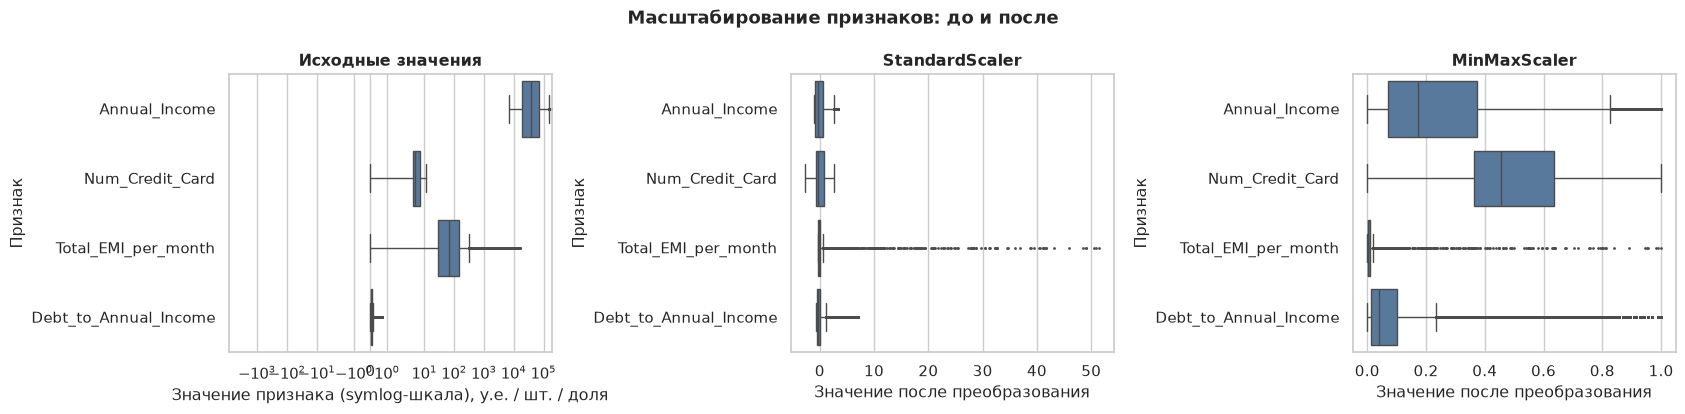

In [6]:
DEMO = ["Annual_Income", "Num_Credit_Card", "Total_EMI_per_month", "Debt_to_Annual_Income"]
demo = X[DEMO]
standard = pd.DataFrame(StandardScaler().fit_transform(demo), columns=DEMO)
minmax = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=DEMO)

summary = pd.concat({
    "исходные": demo.agg(["mean", "std", "min", "median", "max"]),
    "StandardScaler": standard.agg(["mean", "std", "min", "median", "max"]),
    "MinMaxScaler": minmax.agg(["mean", "std", "min", "median", "max"]),
}).round(3)
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (title, frame) in zip(axes, [("Исходные значения", demo), ("StandardScaler", standard),
                                     ("MinMaxScaler", minmax)]):
    sns.boxplot(data=frame, orient="h", ax=ax, color=BASE_COLOR, fliersize=1)
    ax.set_title(title)
    ax.set_xlabel("Значение признака" if title.startswith("Исх") else "Значение после преобразования")
    ax.set_ylabel("Признак")
    if title.startswith("Исх"):
        ax.set_xscale("symlog")
        ax.set_xlabel("Значение признака (symlog-шкала), у.е. / шт. / доля")
plt.suptitle("Масштабирование признаков: до и после", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

После `StandardScaler` все признаки центрированы около 0 с σ = 1 и сравнимы по масштабу. После `MinMaxScaler` медиана `Total_EMI_per_month` ≈ 0.004 — из-за единственного экстремума почти все значения «прижаты» к нулю, что подтверждает выбор стандартизации.

Масштабирование и кодирование встроены в `Pipeline` через `ColumnTransformer`: параметры (μ, σ, список категорий) вычисляются **только на обучающей части** каждого фолда/разбиения, иначе информация из тестовой части «утекла» бы в обучение.

In [7]:
def make_preprocessor(scale):
    numeric_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

### 6.4. Разбиение на обучающую и тестовую выборки

В ЛР2 показано, что у одного клиента 8 почти одинаковых наблюдений, а рейтинг не меняется в 82.5% переходов. Если разбить **по строкам**, один и тот же клиент окажется и в обучении, и в тесте — модель «узнает» его, и качество будет завышено (утечка данных). Это проверим отдельно в 6.8.

Поэтому используем **`GroupShuffleSplit` по `Customer_ID`**: 80% клиентов — обучение, 20% — тест; клиенты не пересекаются. Тест откладываем и используем один раз — для итоговой оценки.

In [8]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train = groups.iloc[train_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
split_info = pd.DataFrame({
    "строк": [len(train_idx), len(test_idx)],
    "клиентов": [groups.iloc[train_idx].nunique(), groups.iloc[test_idx].nunique()],
    **{f"{name}, %": [np.mean(y_train == i) * 100, np.mean(y_test == i) * 100]
       for i, name in enumerate(CLASS_NAMES)},
}, index=["train", "test"])
print("Общих клиентов в train и test:", len(overlap))
split_info.round(2)

Общих клиентов в train и test: 0


,строк,клиентов,"Good, %","Poor, %","Standard, %"
train,80000,10000,17.6700,29.0900,53.2400
test,20000,2500,18.4700,28.6300,52.9000


Клиенты не пересекаются, доли классов в обеих частях практически совпадают — дополнительная стратификация не нужна.

### 6.5. Модели и метрики

**Модели:**

| Модель | Идея | Масштабирование |
|---|---|---|
| Dummy (бейзлайн) | всегда предсказывает самый частый класс `Standard` | — |
| Logistic Regression | линейная модель, softmax по 3 классам; хорошо интерпретируется | нужно |
| Decision Tree | последовательность пороговых правил, ловит нелинейность и взаимодействия | не нужно |
| Random Forest | среднее сотен деревьев на бутстреп-выборках и случайных подмножествах признаков — меньше переобучение | не нужно |
| Gradient Boosting | деревья строятся последовательно, каждое исправляет ошибки предыдущих (`HistGradientBoostingClassifier` — быстрая реализация в scikit-learn, аналог LightGBM) | не нужно |

**Дисбаланс классов** (`Standard` 53%, `Poor` 29%, `Good` 18%) учитываем через `class_weight="balanced"`: ошибка на редком классе штрафуется сильнее.

**Метрики:**
- **macro-F1 — основная.** F1 = гармоническое среднее precision и recall для класса; macro — простое среднее по трём классам, поэтому редкий `Good` весит столько же, сколько `Standard`. Accuracy при дисбалансе обманчива: бейзлайн «всегда Standard» даёт 53% accuracy, ничего не умея.
- **Accuracy** — доля верных ответов, для наглядности.
- **Balanced accuracy** — среднее recall по классам.

RMSE/MAE не используем — это метрики регрессии.

**Кросс-валидация:** `StratifiedGroupKFold` (5 фолдов) на обучающей части — фолды не делят клиентов и сохраняют доли классов.

In [9]:
MODELS = {
    "Dummy (бейзлайн)": Pipeline([("pre", make_preprocessor(False)),
                                  ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("pre", make_preprocessor(True)),
                                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced",
                                                                  random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("pre", make_preprocessor(False)),
                               ("model", DecisionTreeClassifier(max_depth=10, min_samples_leaf=20,
                                                                class_weight="balanced",
                                                                random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("pre", make_preprocessor(False)),
                               ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                class_weight="balanced", n_jobs=-1,
                                                                random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("pre", make_preprocessor(False)),
                                   ("model", HistGradientBoostingClassifier(class_weight="balanced",
                                                                            random_state=RANDOM_STATE))]),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

cv_raw, cv_rows = {}, []
for name, pipeline in MODELS.items():
    start = time.time()
    scores = cross_validate(pipeline, X_train, y_train, groups=groups_train, cv=cv,
                            scoring=SCORING, n_jobs=1, return_train_score=True)
    cv_raw[name] = scores["test_macro_f1"]
    cv_rows.append({
        "модель": name,
        "macro-F1 (CV)": scores["test_macro_f1"].mean(),
        "± std": scores["test_macro_f1"].std(),
        "accuracy (CV)": scores["test_accuracy"].mean(),
        "balanced acc (CV)": scores["test_balanced_accuracy"].mean(),
        "macro-F1 на train": scores["train_macro_f1"].mean(),
        "время, с": time.time() - start,
    })
cv_results = pd.DataFrame(cv_rows).set_index("модель")
cv_results["разрыв train − CV"] = cv_results["macro-F1 на train"] - cv_results["macro-F1 (CV)"]
cv_results.sort_values("macro-F1 (CV)", ascending=False).round(4)

,macro-F1 (CV),± std,accuracy (CV),balanced acc (CV),macro-F1 на train,"время, с",разрыв train − CV
модель,,,,,,,
Random Forest,0.6860,0.0060,0.6951,0.7269,0.9268,25.5722,0.2407
Gradient Boosting,0.6797,0.0034,0.6872,0.7250,0.7884,17.0199,0.1087
Decision Tree,0.6621,0.0029,0.6685,0.7111,0.7068,5.3637,0.0447
Logistic Regression,0.6532,0.0035,0.6616,0.7007,0.6554,14.8061,0.0022
Dummy (бейзлайн),0.2316,0.0000,0.5324,0.3333,0.2316,2.1059,0.0000


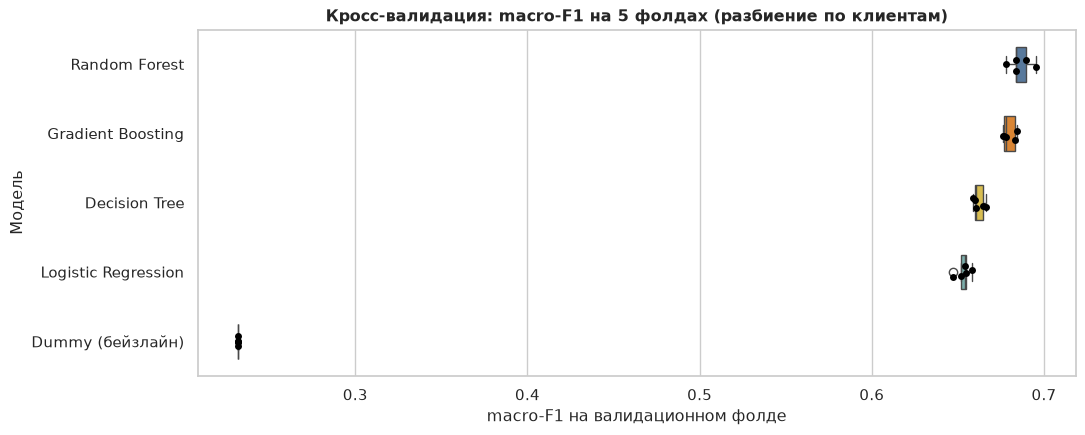

In [10]:
cv_long = pd.DataFrame(cv_raw).melt(var_name="модель", value_name="macro-F1")
order = cv_results.sort_values("macro-F1 (CV)", ascending=False).index

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=cv_long, y="модель", x="macro-F1", order=order, hue="модель", hue_order=order,
            palette=MODEL_COLORS, legend=False, dodge=False, width=0.5, ax=ax)
sns.stripplot(data=cv_long, y="модель", x="macro-F1", order=order, color="black", size=5, ax=ax)
ax.set_title("Кросс-валидация: macro-F1 на 5 фолдах (разбиение по клиентам)")
ax.set_xlabel("macro-F1 на валидационном фолде")
ax.set_ylabel("Модель")
plt.tight_layout()
plt.show()

**Результаты кросс-валидации:**

- Все модели многократно превосходят бейзлайн (macro-F1 0.23): даже простая логистическая регрессия даёт 0.65.
- Лучшие — ансамбли: **Random Forest 0.686 ± 0.006** и **Gradient Boosting 0.680 ± 0.003**. Разброс между фолдами мал (std < 0.01), т.е. оценки устойчивы и различие моделей не случайно.
- Деревья выигрывают у линейной модели (+0.03): связи нелинейные и ступенчатые (ЛР2), есть взаимодействия признаков.
- **Переобучение:** у Random Forest macro-F1 на обучении 0.93 против 0.69 на валидации — лес «запоминает» обучающих клиентов, но это не мешает ему лучше всех обобщать. У логистической регрессии разрыва нет (0.655 / 0.653) — она недообучена: её линейная граница слишком проста для данных.

### 6.6. Подбор гиперпараметров

Подбираем гиперпараметры двух лучших ансамблей с помощью `GridSearchCV` на тех же групповых фолдах (3 фолда — для экономии времени). Сетки небольшие и затрагивают параметры, сильнее всего влияющие на баланс «недообучение ↔ переобучение»: глубина/размер листа и доля признаков для леса, скорость обучения и число деревьев для бустинга.

In [11]:
search_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SEARCHES = {
    "Random Forest": {
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 3],
        "model__max_features": ["sqrt", 0.4],
    },
    "Gradient Boosting": {
        "model__learning_rate": [0.05, 0.1],
        "model__max_iter": [200, 400],
        "model__max_leaf_nodes": [31, 63],
    },
}
searches = {}
for name, grid in SEARCHES.items():
    start = time.time()
    search = GridSearchCV(MODELS[name], grid, scoring="f1_macro", cv=search_cv, n_jobs=1, refit=True)
    search.fit(X_train, y_train, groups=groups_train)
    searches[name] = search
    print(f"{name}: лучший macro-F1 (CV) = {search.best_score_:.4f}, "
          f"параметры = {search.best_params_}, время {time.time() - start:.0f} с")

pd.concat({
    name: pd.DataFrame(s.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
              .sort_values("rank_test_score").head(4)
    for name, s in searches.items()
})

Random Forest: лучший macro-F1 (CV) = 0.6853, параметры = {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}, время 169 с


Gradient Boosting: лучший macro-F1 (CV) = 0.6805, параметры = {'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 63}, время 144 с


params  \
Random Forest     0  {'model__max_depth': None, 'model__max_feature...   
                  6  {'model__max_depth': 20, 'model__max_features'...   
                  3  {'model__max_depth': None, 'model__max_feature...   
                  7  {'model__max_depth': 20, 'model__max_features'...   
Gradient Boosting 1  {'model__learning_rate': 0.05, 'model__max_ite...   
                  0  {'model__learning_rate': 0.05, 'model__max_ite...   
                  2  {'model__learning_rate': 0.05, 'model__max_ite...   
                  3  {'model__learning_rate': 0.05, 'model__max_ite...   

                     mean_test_score  std_test_score  rank_test_score  
Random Forest     0           0.6853          0.0039                1  
                  6           0.6850          0.0041                2  
                  3           0.6849          0.0022                3  
                  7           0.6842          0.0032                4  
Gradient Boosting 1           0.6805          0.0052                1  
                  0           0.6797          0.0038                2  
                  2           0.6794          0.0045                3  
                  3           0.6786          0.0031                4

Подбор гиперпараметров почти не изменил качество: лучшие комбинации отличаются от значений по умолчанию на тысячные доли macro-F1 (в пределах std между фолдами). Значит, модели уже близки к потолку качества, который дают имеющиеся признаки, — для заметного улучшения нужны новые данные, а не перебор параметров. Для леса лучшими оказались неограниченная глубина и `max_features="sqrt"`, для бустинга — `learning_rate=0.05`, 200 деревьев, 63 листа.

### 6.7. Итоговая оценка на отложенных клиентах

Обучаем все модели на всей обучающей части (для ансамблей — с подобранными параметрами) и **один раз** оцениваем на 20% отложенных клиентов.

In [12]:
final_models = dict(MODELS)
for name, search in searches.items():
    final_models[name] = search.best_estimator_

test_rows, test_predictions = [], {}
for name, pipeline in final_models.items():
    if name not in searches:
        pipeline.fit(X_train, y_train)
    prediction = pipeline.predict(X_test)
    test_predictions[name] = prediction
    per_class = f1_score(y_test, prediction, average=None)
    test_rows.append({
        "модель": name,
        "macro-F1": f1_score(y_test, prediction, average="macro"),
        "accuracy": accuracy_score(y_test, prediction),
        "balanced acc": balanced_accuracy_score(y_test, prediction),
        **{f"F1 {cls}": per_class[i] for i, cls in enumerate(CLASS_NAMES)},
    })
test_results = pd.DataFrame(test_rows).set_index("модель").sort_values("macro-F1", ascending=False)
BEST_NAME = test_results.index[0]
best_model = final_models[BEST_NAME]
best_pred = test_predictions[BEST_NAME]
print("Лучшая модель на тесте:", BEST_NAME)
test_results.round(4)

Лучшая модель на тесте: Random Forest


,macro-F1,accuracy,balanced acc,F1 Good,F1 Poor,F1 Standard
модель,,,,,,
Random Forest,0.6958,0.7032,0.7305,0.6573,0.7079,0.7222
Gradient Boosting,0.6946,0.7006,0.7343,0.6607,0.7077,0.7154
Decision Tree,0.6704,0.6733,0.7248,0.6408,0.6983,0.6721
Logistic Regression,0.6630,0.6690,0.7059,0.6364,0.6623,0.6902
Dummy (бейзлайн),0.2307,0.5290,0.3333,0.0000,0.0000,0.6920


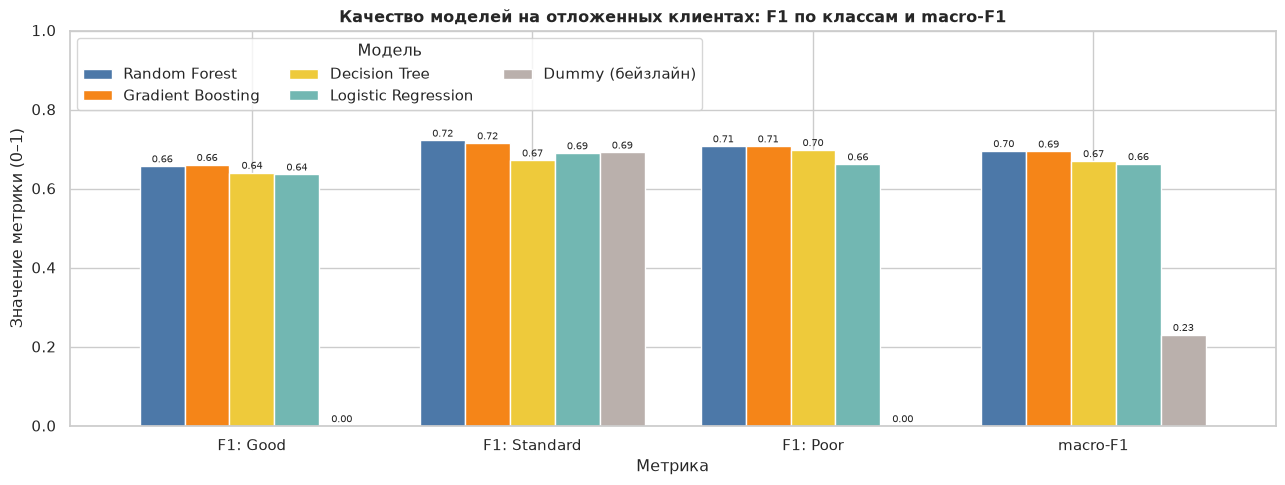

In [13]:
plot_data = test_results[["F1 Good", "F1 Standard", "F1 Poor", "macro-F1"]].rename(
    columns=lambda c: c.replace("F1 ", "F1: "))
fig, ax = plt.subplots(figsize=(13, 5))
plot_data.T.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in plot_data.index],
                 width=0.8, edgecolor="white")
ax.set_title("Качество моделей на отложенных клиентах: F1 по классам и macro-F1")
ax.set_xlabel("Метрика")
ax.set_ylabel("Значение метрики (0–1)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Модель", loc="upper left", ncol=3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=1)
plt.tight_layout()
plt.show()

Отчёт по классам для модели «Random Forest»:

              precision    recall  f1-score   support

        Good      0.555     0.806     0.657      3694
        Poor      0.682     0.736     0.708      5726
    Standard      0.813     0.650     0.722     10580

    accuracy                          0.703     20000
   macro avg      0.683     0.731     0.696     20000
weighted avg      0.728     0.703     0.706     20000



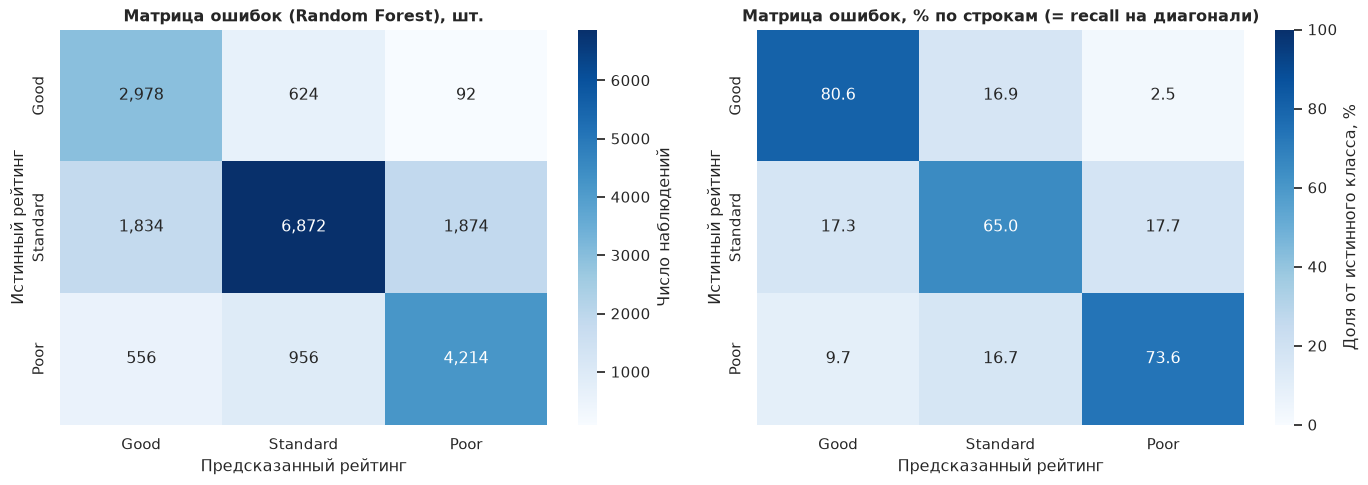

In [14]:
print(f"Отчёт по классам для модели «{BEST_NAME}»:\n")
print(classification_report(y_test, best_pred, target_names=CLASS_NAMES, digits=3))

display_order = [CLASS_NAMES.index(c) for c in SCORE_ORDER]
cm = confusion_matrix(y_test, best_pred, labels=display_order)
cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=SCORE_ORDER, yticklabels=SCORE_ORDER,
            cbar_kws={"label": "Число наблюдений"}, ax=axes[0])
axes[0].set_title(f"Матрица ошибок ({BEST_NAME}), шт.")
sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            xticklabels=SCORE_ORDER, yticklabels=SCORE_ORDER,
            cbar_kws={"label": "Доля от истинного класса, %"}, ax=axes[1])
axes[1].set_title("Матрица ошибок, % по строкам (= recall на диагонали)")
for ax in axes:
    ax.set_xlabel("Предсказанный рейтинг")
    ax.set_ylabel("Истинный рейтинг")
plt.tight_layout()
plt.show()

**Итог на отложенных клиентах:** лучшая модель — **Random Forest: macro-F1 = 0.696, accuracy = 0.703, balanced accuracy = 0.731**; Gradient Boosting практически равен ему (0.695). Результат теста совпадает с кросс-валидацией (0.686), т.е. оценка не переоптимистична. Цель проекта — превзойти бейзлайн (0.23) по macro-F1 — **достигнута**, качество выше в 3 раза.

**По классам:**
- `Good`: высокий recall (0.81), но низкая precision (0.56) — из-за `class_weight="balanced"` модель охотно присваивает редкий класс `Good`, и почти половина «хороших» прогнозов — на самом деле `Standard`.
- `Standard`: наоборот, высокая precision (0.81) и самый низкий recall (0.65) — средний класс модель «раздаёт» соседям.
- `Poor`: сбалансирован (precision 0.68, recall 0.74).

Для банка это значит: модель хорошо **находит** рискованных клиентов (74% `Poor` распознаны), но прогноз `Good` нельзя использовать как автоматическое одобрение без дополнительной проверки.

### 6.8. Проверка утечки: разбиение по строкам vs по клиентам

Обучим ту же лучшую модель, но разобьём данные **случайно по строкам** (как сделали бы «по умолчанию» с `train_test_split`).

In [15]:
row_train, row_test = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y,
                                       random_state=RANDOM_STATE)
leaky_model = clone(final_models[BEST_NAME])
leaky_model.fit(X.iloc[row_train], y[row_train])
leaky_f1 = f1_score(y[row_test], leaky_model.predict(X.iloc[row_test]), average="macro")
shared = len(set(groups.iloc[row_train]) & set(groups.iloc[row_test]))

leak = pd.DataFrame({
    "macro-F1 на тесте": [leaky_f1, test_results.loc[BEST_NAME, "macro-F1"]],
    "клиентов теста, встречавшихся в обучении": [shared, 0],
}, index=["случайно по строкам (утечка)", "по клиентам (корректно)"])
display(leak.round(4))
print(f"Завышение оценки при разбиении по строкам: "
      f"+{leaky_f1 - test_results.loc[BEST_NAME, 'macro-F1']:.3f} macro-F1")

,macro-F1 на тесте,"клиентов теста, встречавшихся в обучении"
случайно по строкам (утечка),0.8265,10449
по клиентам (корректно),0.6958,0


Завышение оценки при разбиении по строкам: +0.131 macro-F1


При случайном разбиении по строкам практически каждый клиент тестовой части (10 449 клиентов) уже «виден» модели в обучении — по другим своим месяцам, и macro-F1 **завышается до 0.83 (+0.13)**. Модель не обобщает закономерность, а узнаёт конкретного клиента по его почти неизменным признакам. На новых клиентах банка такой модели следует ожидать ≈ 0.70, а не 0.83. Это подтверждает решение разбивать данные по `Customer_ID`.

### 6.9. Анализ ошибок

In [16]:
analysis = X_test.copy()
analysis["true"] = target_encoder.inverse_transform(y_test)
analysis["pred"] = target_encoder.inverse_transform(best_pred)
analysis["error"] = analysis["true"] != analysis["pred"]
proba = best_model.predict_proba(X_test)
analysis["confidence"] = proba.max(axis=1)
rank = {"Poor": 0, "Standard": 1, "Good": 2}
analysis["error_type"] = np.select(
    [~analysis["error"],
     (analysis["true"].map(rank) - analysis["pred"].map(rank)).abs() == 2,
     analysis["pred"].map(rank) > analysis["true"].map(rank)],
    ["верно", "грубая (Good ↔ Poor)", "завышение рейтинга"], default="занижение рейтинга")

display(analysis["error_type"].value_counts(normalize=True).mul(100).round(2).to_frame("доля, %"))

pairs = (analysis[analysis["error"]].groupby(["true", "pred"]).size()
         .sort_values(ascending=False).rename("ошибок").to_frame())
pairs["доля от всех ошибок, %"] = pairs["ошибок"] / pairs["ошибок"].sum() * 100
pairs.round(1)

,"доля, %"
error_type,
верно,70.3200
завышение рейтинга,13.9500
занижение рейтинга,12.4900
грубая (Good ↔ Poor),3.2400


ошибок  доля от всех ошибок, %
true     pred                                    
Standard Poor        1874                 31.6000
         Good        1834                 30.9000
Poor     Standard     956                 16.1000
Good     Standard     624                 10.5000
Poor     Good         556                  9.4000
Good     Poor          92                  1.5000

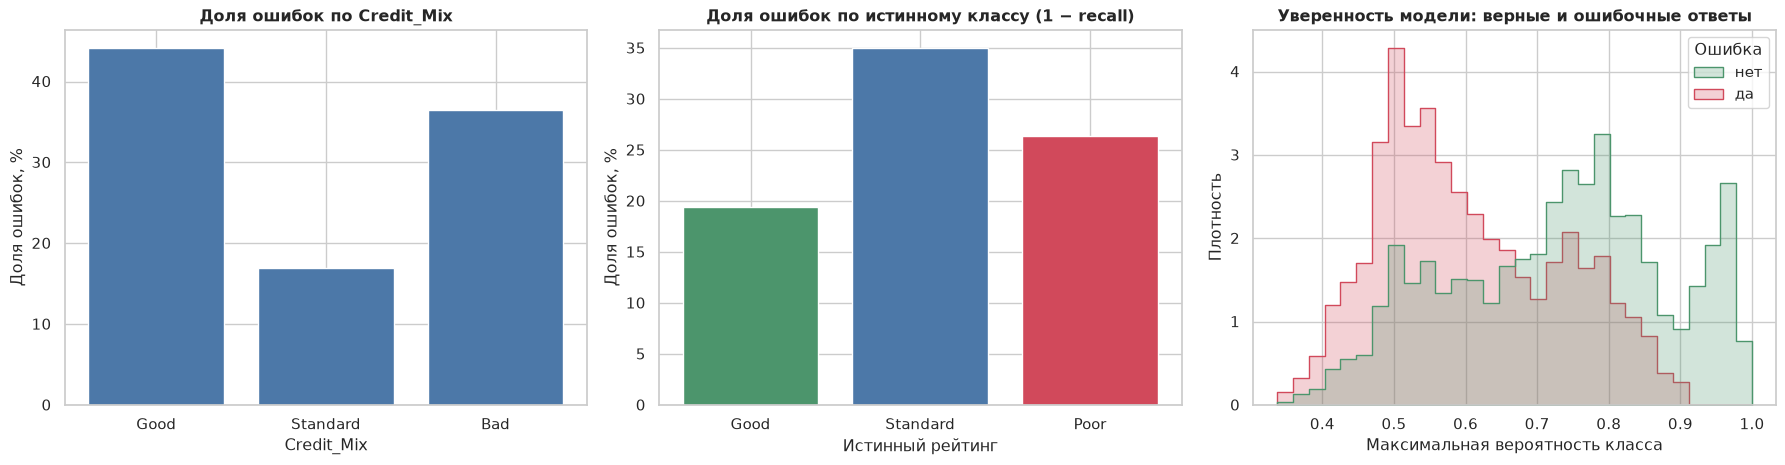

,наблюдений,доля ошибок
уверенность модели,,
"(0.0, 0.5]",2570,0.5300
"(0.5, 0.7]",7465,0.4070
"(0.7, 0.9]",7710,0.1980
"(0.9, 1.0]",2255,0.0040


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

by_mix = analysis.groupby("Credit_Mix")["error"].mean().reindex(["Good", "Standard", "Bad"]) * 100
axes[0].bar(by_mix.index, by_mix.values, color=BASE_COLOR)
axes[0].set_title("Доля ошибок по Credit_Mix")
axes[0].set_xlabel("Credit_Mix")
axes[0].set_ylabel("Доля ошибок, %")

by_true = analysis.groupby("true")["error"].mean().reindex(SCORE_ORDER) * 100
axes[1].bar(by_true.index, by_true.values, color=[SCORE_COLORS[s] for s in SCORE_ORDER])
axes[1].set_title("Доля ошибок по истинному классу (1 − recall)")
axes[1].set_xlabel("Истинный рейтинг")
axes[1].set_ylabel("Доля ошибок, %")

sns.histplot(data=analysis, x="confidence", hue="error", bins=30, stat="density", common_norm=False,
             element="step", palette={False: SCORE_COLORS["Good"], True: SCORE_COLORS["Poor"]},
             ax=axes[2])
axes[2].set_title("Уверенность модели: верные и ошибочные ответы")
axes[2].set_xlabel("Максимальная вероятность класса")
axes[2].set_ylabel("Плотность")
axes[2].get_legend().set_title("Ошибка")
for text, new in zip(axes[2].get_legend().texts, ["нет", "да"]):
    text.set_text(new)
plt.tight_layout()
plt.show()

conf_bins = pd.cut(analysis["confidence"], [0, 0.5, 0.7, 0.9, 1.0])
display(analysis.groupby(conf_bins, observed=True)["error"]
        .agg(["size", "mean"]).rename(columns={"size": "наблюдений", "mean": "доля ошибок"})
        .rename_axis("уверенность модели").round(3))

In [18]:
# Чем отличаются клиенты, на которых модель ошибается, от тех, где она права (класс Standard)?
compare_cols = ["Interest_Rate", "Outstanding_Debt", "Delay_from_due_date",
                "Num_Credit_Inquiries", "Credit_History_Months"]
standard_rows = analysis[analysis["true"] == "Standard"]
(standard_rows.groupby("pred")[compare_cols].median()
 .reindex(SCORE_ORDER)
 .rename_axis("Истинный Standard, предсказан как")
 .round(1))

,Interest_Rate,Outstanding_Debt,Delay_from_due_date,Num_Credit_Inquiries,Credit_History_Months
"Истинный Standard, предсказан как",,,,,
Good,7.0000,625.1000,8.0000,3.0000,293.0000
Standard,13.0000,875.1000,19.0000,5.0000,232.5000
Poor,23.0000,"2,538.1000",33.0000,10.0000,125.0000


**Выводы по ошибкам:**

- 70.3% ответов верны; **грубые ошибки (`Good` ↔ `Poor`) — всего 3.2%**, остальные ошибки — между соседними классами. Из них 62.5% — это истинный `Standard`, предсказанный как `Poor` (31.6%) или `Good` (30.9%).
- Ошибки на `Standard` объяснимы: такие клиенты по признакам действительно похожи на соседний класс. «Standard → Poor» имеют медианную ставку 23%, долг ≈ 2 540 у.е. и просрочку 33 дня — типичный профиль `Poor`; «Standard → Good» — ставку 7%, долг ≈ 625 у.е., просрочку 8 дней — профиль `Good`. Имеющиеся признаки не позволяют отличить таких клиентов; вероятно, у банка есть информация, которой нет в наборе.
- **По `Credit_Mix`** ошибок меньше всего при `Standard` (≈ 17%): в этой категории 65% клиентов — `Standard`, и модель редко ошибается. При `Good` (≈ 44%) и `Bad` (≈ 36%) ошибок больше: эти категории смешивают соседние классы (`Good`: 45% Good / 39% Standard; `Bad`: 56% Poor / 42% Standard), и разделить их другими признаками сложно.
- **Уверенность модели информативна:** при вероятности > 0.9 доля ошибок всего 0.4%, при 0.7–0.9 — 20%, а при < 0.5 — 53%. Практический вывод: прогнозы с высокой уверенностью можно использовать автоматически, а клиентов с уверенностью < 0.7 (≈ 50% выборки) — направлять на ручную проверку.

### 6.10. Важность признаков

**Permutation importance** — модельно-независимый способ: на тестовой выборке перемешиваем значения одного признака и смотрим, насколько падает macro-F1. Чем сильнее падение, тем важнее признак. Перемешивание выполняется для **исходного** столбца до кодирования, поэтому one-hot категории одного признака оцениваются вместе.

Время расчёта: 23 с


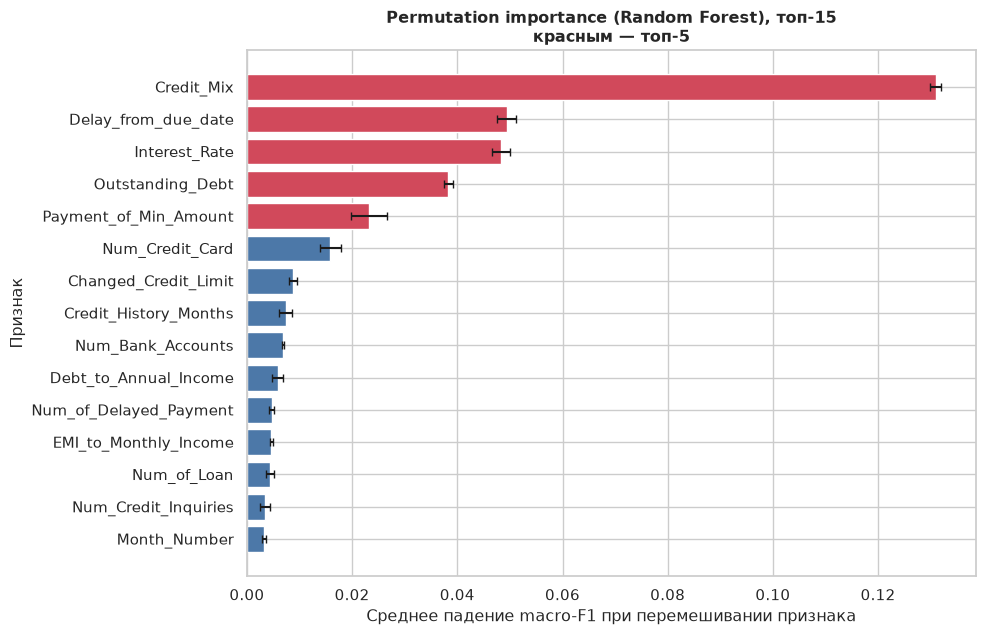

,падение macro-F1,std
Credit_Mix,0.1309,0.0011
Delay_from_due_date,0.0494,0.0019
Interest_Rate,0.0482,0.0017
Outstanding_Debt,0.0383,0.0009
Payment_of_Min_Amount,0.0233,0.0034
Num_Credit_Card,0.0159,0.0020
Changed_Credit_Limit,0.0088,0.0008
Credit_History_Months,0.0074,0.0013
Num_Bank_Accounts,0.0069,0.0002
Debt_to_Annual_Income,0.0059,0.0011


In [19]:
start = time.time()
perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"падение macro-F1": perm.importances_mean, "std": perm.importances_std},
                           index=X_test.columns)
              .sort_values("падение macro-F1", ascending=False))
print(f"Время расчёта: {time.time() - start:.0f} с")

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [SCORE_COLORS["Poor"] if name in importance.index[:5] else BASE_COLOR for name in top.index]
ax.barh(top.index, top["падение macro-F1"], xerr=top["std"], color=colors, capsize=3)
ax.set_title(f"Permutation importance ({BEST_NAME}), топ-15\nкрасным — топ-5")
ax.set_xlabel("Среднее падение macro-F1 при перемешивании признака")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()
importance.head(15).round(4)

**Топ-5 признаков Random Forest:** `Credit_Mix` (перемешивание снижает macro-F1 на 0.131 — в 2.6 раза больше, чем любой другой признак), `Delay_from_due_date` (0.049), `Interest_Rate` (0.048), `Outstanding_Debt` (0.038), `Payment_of_Min_Amount` (0.023). Остальные признаки дают < 0.016 каждый; признаки «типов кредитов», профессии и возраста в топ-15 не вошли.

Permutation importance занижает важность **коррелированных** признаков: если перемешать один из группы, модель частично восстанавливает информацию по остальным. Так, `Num_Credit_Inquiries` (большой эффект в ЛР2, ε² = 0.14) оказался лишь 14-м, потому что сильно коррелирует со ставкой (ρ = 0.61) и длительностью истории (ρ = −0.62).

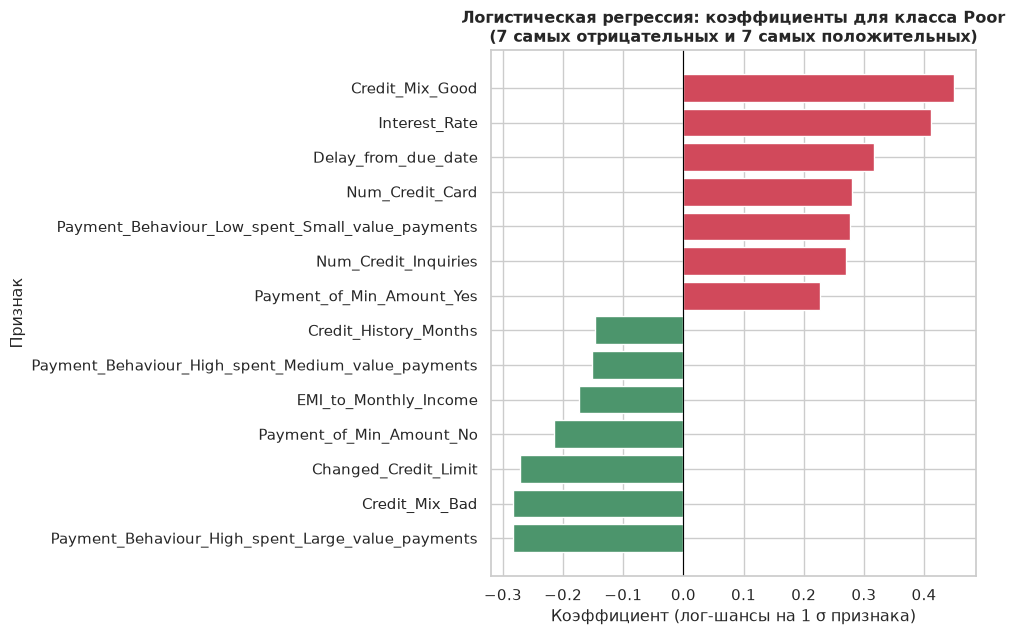

In [20]:
# Коэффициенты логистической регрессии: признаки стандартизированы, поэтому их можно сравнивать.
log_reg = final_models["Logistic Regression"]
feature_names = log_reg.named_steps["pre"].get_feature_names_out()
coefs = pd.DataFrame(log_reg.named_steps["model"].coef_.T, index=feature_names, columns=CLASS_NAMES)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
poor_coefs = coefs["Poor"].sort_values()
shown = pd.concat([poor_coefs.head(7), poor_coefs.tail(7)])

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(shown.index, shown.values,
        color=[SCORE_COLORS["Poor"] if v > 0 else SCORE_COLORS["Good"] for v in shown])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Логистическая регрессия: коэффициенты для класса Poor\n(7 самых отрицательных и 7 самых положительных)")
ax.set_xlabel("Коэффициент (лог-шансы на 1 σ признака)")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

Знаки большинства коэффициентов логистической регрессии ожидаемы: ставка, просрочка, число карт и запросов, оплата только минимального платежа (`Payment_of_Min_Amount_Yes`) увеличивают шанс `Poor`; длинная история и крупные платежи (`High_spent_Large_value_payments`) — уменьшают.

**Неожиданный результат:** `Credit_Mix_Good` *увеличивает*, а `Credit_Mix_Bad` *уменьшает* шанс `Poor` — противоположно H3. Коэффициент регрессии показывает влияние признака **при прочих равных**, поэтому проверим, как связан `Credit_Mix` с `Poor` внутри групп с одинаковой ставкой.

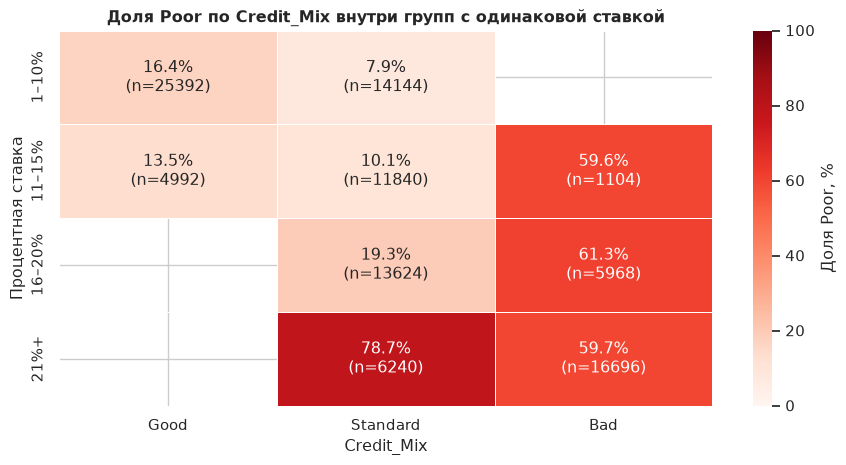

Доля Poor без учёта ставки, %: {'Good': 16.0, 'Standard': 21.5, 'Bad': 60.1}


In [21]:
check = train_df.assign(
    is_poor=train_df["Credit_Score"].eq("Poor"),
    rate_band=pd.cut(train_df["Interest_Rate"], [0, 10, 15, 20, 40],
                     labels=["1–10%", "11–15%", "16–20%", "21%+"]))
simpson_share = (check.pivot_table(index="rate_band", columns="Credit_Mix", values="is_poor",
                                   aggfunc="mean", observed=True)
                 .reindex(columns=["Good", "Standard", "Bad"]) * 100)
simpson_size = (check.pivot_table(index="rate_band", columns="Credit_Mix", values="ID",
                                  aggfunc="count", observed=True)
                .reindex(columns=["Good", "Standard", "Bad"]))
overall = check.groupby("Credit_Mix")["is_poor"].mean().reindex(["Good", "Standard", "Bad"]) * 100

annotations = (simpson_share.round(1).astype(str) + "%\n(n=" +
               simpson_size.fillna(0).astype(int).astype(str) + ")").where(simpson_size.notna(), "нет\nклиентов")
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(simpson_share, annot=annotations, fmt="", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "Доля Poor, %"}, linewidths=0.5, ax=ax)
ax.set_title("Доля Poor по Credit_Mix внутри групп с одинаковой ставкой")
ax.set_xlabel("Credit_Mix")
ax.set_ylabel("Процентная ставка")
plt.tight_layout()
plt.show()
print("Доля Poor без учёта ставки, %:", overall.round(1).to_dict())

Это **парадокс Симпсона**. В целом при `Credit_Mix = Good` доля `Poor` наименьшая, а при `Bad` — наибольшая (H3 верна для сырой связи). Но `Credit_Mix` почти целиком определяется ставкой: `Good` встречается только при ставке ≤ 15%, `Bad` — только при ставке > 10%. **Внутри одной группы ставки** картина другая: при ставке 1–10% доля `Poor` у `Good` (≈ 16%) вдвое выше, чем у `Standard` (≈ 8%), а при ставке 21%+ у `Bad` (≈ 60%) — ниже, чем у `Standard` (≈ 79%).

Следствия:
1. `Credit_Mix` — не самостоятельная причина, а **сводная оценка, вычисленная из тех же факторов** (ставка, долг, просрочки). Поэтому модель так сильно на него опирается: это почти «готовый» рейтинг.
2. Интерпретировать отдельные коэффициенты логистической регрессии как «влияние» нельзя: признаки сильно коррелированы, и знак может развернуться. Для объяснения решений надёжнее permutation importance и сравнение групп.
3. Такая жёсткая связь (`Good` строго при ставке ≤ 15%) — ещё один признак синтетической генерации данных.

In [22]:
# Сверка топ-5 модели с топ-5 статистического анализа ЛР2.
LR2_TOP5 = ["Interest_Rate", "Outstanding_Debt", "Delay_from_due_date", "Num_Credit_Inquiries", "Credit_Mix"]
model_top5 = list(importance.index[:5])
comparison = pd.DataFrame({
    "ЛР2 (размер эффекта)": LR2_TOP5,
    f"ЛР3 ({BEST_NAME}, permutation)": model_top5,
}, index=range(1, 6))
display(comparison)
print("Совпадают:", sorted(set(LR2_TOP5) & set(model_top5)))
print("Ранг признаков ЛР2 в модели:",
      {f: int(importance.index.get_loc(f)) + 1 for f in LR2_TOP5})

,ЛР2 (размер эффекта),"ЛР3 (Random Forest, permutation)"
1,Interest_Rate,Credit_Mix
2,Outstanding_Debt,Delay_from_due_date
3,Delay_from_due_date,Interest_Rate
4,Num_Credit_Inquiries,Outstanding_Debt
5,Credit_Mix,Payment_of_Min_Amount


Совпадают: ['Credit_Mix', 'Delay_from_due_date', 'Interest_Rate', 'Outstanding_Debt']
Ранг признаков ЛР2 в модели: {'Interest_Rate': 3, 'Outstanding_Debt': 4, 'Delay_from_due_date': 2, 'Num_Credit_Inquiries': 14, 'Credit_Mix': 1}


**Сверка с ЛР2:** 4 из 5 факторов совпали — `Credit_Mix`, `Delay_from_due_date`, `Interest_Rate`, `Outstanding_Debt`. Место `Num_Credit_Inquiries` (ЛР2) в модели занял `Payment_of_Min_Amount` — второй по силе категориальный фактор ЛР2 (V = 0.27); число запросов «растворилось» в коррелированных с ним ставке и истории. Два независимых метода — статистические тесты на срезе и важность признаков модели на отложенных клиентах — дают согласованный список, поэтому его можно считать надёжным.

### 6.11. Прогноз для периода сентябрь–декабрь

`test.csv` из архива не содержит целевой переменной, поэтому качество на нём оценить нельзя. Обучаем лучшую модель на **всех** размеченных данных и строим прогноз на будущие месяцы — так модель использовалась бы на практике.

Сохранено: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/modeling-conclusions/credit_score_test_predictions.csv (50000, 4)


,"янв–авг (факт), %","сен–дек (прогноз), %"
Good,17.8300,23.0000
Standard,53.1700,44.0200
Poor,29.0000,32.9800


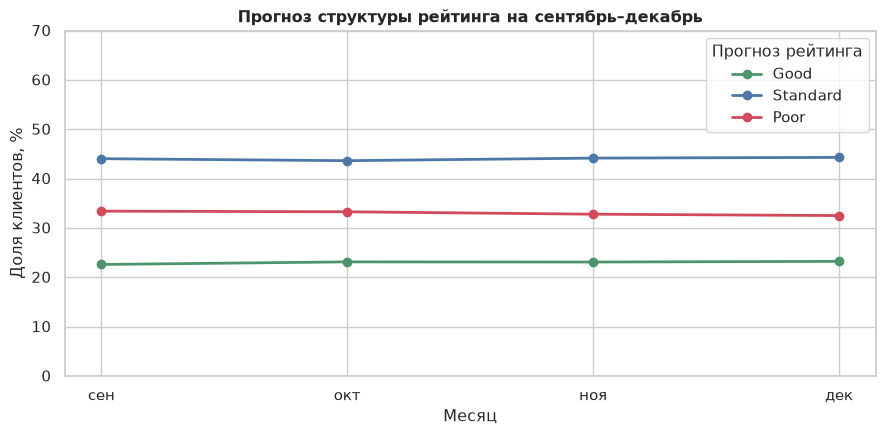

In [23]:
production_model = clone(best_model)
production_model.fit(X, y)
future_pred = target_encoder.inverse_transform(production_model.predict(X_future))
future_out = future_df[["ID", "Customer_ID", "Month"]].assign(Predicted_Credit_Score=future_pred)

output_path = Path("credit_score_test_predictions.csv")
future_out.to_csv(output_path, index=False)
print("Сохранено:", output_path.resolve(), future_out.shape)

shares = pd.DataFrame({
    "янв–авг (факт), %": train_df["Credit_Score"].value_counts(normalize=True).mul(100),
    "сен–дек (прогноз), %": future_out["Predicted_Credit_Score"].value_counts(normalize=True).mul(100),
}).reindex(SCORE_ORDER).round(2)
display(shares)

month_order = ["September", "October", "November", "December"]
by_month = (pd.crosstab(future_out["Month"], future_out["Predicted_Credit_Score"], normalize="index")
            .reindex(index=month_order, columns=SCORE_ORDER).mul(100))
fig, ax = plt.subplots(figsize=(9, 4.5))
for score in SCORE_ORDER:
    ax.plot(["сен", "окт", "ноя", "дек"], by_month[score], marker="o", linewidth=2,
            color=SCORE_COLORS[score], label=score)
ax.set_title("Прогноз структуры рейтинга на сентябрь–декабрь")
ax.set_xlabel("Месяц")
ax.set_ylabel("Доля клиентов, %")
ax.set_ylim(0, 70)
ax.legend(title="Прогноз рейтинга")
plt.tight_layout()
plt.show()

Прогноз на сентябрь–декабрь сдвинут относительно фактической структуры января–августа: `Good` 23.0% (факт 17.8%), `Standard` 44.0% (53.2%), `Poor` 33.0% (29.0%). Это **не** прогноз ухудшения портфеля, а следствие `class_weight="balanced"`: модель сознательно чаще выбирает редкие классы (recall `Good` 0.81 при precision 0.56, см. 6.7) и реже — `Standard`. Для оценки *структуры портфеля* нужно использовать модель без балансировки весов или калиброванные вероятности; для поиска *рискованных клиентов* текущая настройка, наоборот, удобна.

## 7. Итоговые выводы по проекту

Цель проекта, поставленная в ЛР1: выявить топ-5 факторов, сильнее всего связанных с `Credit_Score`, и построить классификатор, превосходящий наивный бейзлайн по macro-F1 на новых клиентах. **Обе части цели достигнуты.**

### 7.1. Подтверждение и опровержение гипотез

| Гипотеза | Вывод | Факты (ЛР2 — тесты на срезе августа, n = 12 500; ЛР3 — модель) |
|---|---|---|
| **H1.** Больший долг и более длительные просрочки связаны с худшим рейтингом | **подтверждена** | Медиана долга `Good` / `Standard` / `Poor`: 747 / 1 041 / 1 826 у.е.; просрочки: 11 / 18 / 26 дней. Краскел–Уоллис p < 10⁻³⁰⁰, ε² = 0.15 (большой эффект). В модели просрочка — 2-й, долг — 4-й по важности признак. |
| **H2.** Высокая ставка чаще у `Poor` | **подтверждена** | Медиана ставки 8% / 13% / 20%; ε² = 0.18 — наибольший эффект среди числовых признаков; ρ Спирмена с рейтингом −0.42. 3-й признак модели. |
| **H3.** `Credit_Mix = Bad` связан с худшим рейтингом | **подтверждена для общей связи, с оговоркой** | При `Bad` доля `Poor` 55.6% против 16.0% при `Good`; V Крамера = 0.36, OR = 4.86 (p ≈ 10⁻²⁷⁸). Самый важный признак модели. Однако внутри групп с одинаковой ставкой связь разворачивается (парадокс Симпсона): `Credit_Mix` — производная оценка от ставки и долга, а не самостоятельный фактор. |
| **H4.** Частые кредитные запросы связаны с худшим рейтингом | **подтверждена** | Медиана запросов 4 / 6 / 9; ε² = 0.14 (большой эффект). В модели — лишь 14-е место: информация о запросах дублируется ставкой (ρ = 0.61) и длительностью истории (ρ = −0.62). |
| **H5.** Большая доля EMI в доходе связана с худшим рейтингом | **подтверждена частично** | Направление совпадает (медиана 1.9% / 2.4% / 3.4% дохода), различие значимо (p ≈ 10⁻¹²⁰), но ε² = 0.04 — эффект малый; в модели вклад признака 0.005 macro-F1. Самостоятельной практической ценности фактор почти не имеет. |

### 7.2. Ключевые находки

1. **Топ-5 факторов кредитного рейтинга**, согласованно выделенных двумя независимыми методами (статистические тесты — ЛР2, permutation importance модели — ЛР3; совпадение 4 из 5): **структура кредитов `Credit_Mix`, процентная ставка, длительность просрочки, сумма непогашенного долга** и — по модели — **оплата только минимального платежа** (`Payment_of_Min_Amount`). Все связи монотонные, умеренной силы (|ρ| = 0.38–0.42), нелинейные и ступенчатые.
2. **Профессия, возраст и доход практически не определяют рейтинг**: профессия статистически не связана с рейтингом (χ², p = 0.74), возраст и доход дают малый эффект (ε² ≤ 0.04). Рейтинг определяется **кредитным поведением**, а не социально-демографическим профилем.
3. **Лучшая модель — Random Forest**: macro-F1 = 0.696, accuracy = 0.703, balanced accuracy = 0.731 на 2 500 клиентах, не участвовавших в обучении (бейзлайн — 0.231). Gradient Boosting даёт практически то же качество (0.695), логистическая регрессия — 0.663. Подбор гиперпараметров меняет результат лишь на тысячные доли: качество ограничено информативностью признаков.
4. **Ошибки модели почти всегда «соседние»**: грубые ошибки `Good` ↔ `Poor` составляют 3.2% прогнозов; 62.5% ошибок приходятся на истинный `Standard`. Вероятность модели информативна: при уверенности > 0.9 доля ошибок 0.4%, при < 0.5 — 53%.
5. **Разбиение по клиентам обязательно**: случайное разбиение по строкам завышает macro-F1 с 0.696 до 0.827 (+0.13) за счёт того, что модель «узнаёт» клиентов по другим месяцам.
6. **Временная динамика**: сезонности за январь–август нет; с апреля доля `Good` ступенчато выросла с 15.9% до 19.0% (χ², p ≈ 10⁻³⁵), а медиана кредитных запросов — с 4 до 6. Рейтинг клиента стабилен: 82.5% переходов месяц → месяц без изменений.

### 7.3. Практические рекомендации заказчику

**Для процесса кредитного скоринга (банк):**
1. В первую очередь анализировать **процентную ставку, длительность просрочки, сумму долга и факт оплаты только минимального платежа** — эти четыре показателя вместе с `Credit_Mix` дают основную часть качества модели. Профессию в скоринге можно не учитывать: она не связана с рейтингом и создаёт риск необоснованной дискриминации.
2. Использовать модель как **инструмент сортировки заявок**, а не как автоматическое решение: прогнозы с вероятностью > 0.9 (≈ 11% клиентов, 0.4% ошибок) обрабатывать автоматически, клиентов с вероятностью < 0.7 (≈ 50%) направлять на ручную проверку.
3. Прогноз `Good` не использовать для автоматического одобрения: его precision 0.56 — почти половина таких клиентов на самом деле `Standard`. Для поиска рискованных клиентов модель пригодна: распознаёт 74% `Poor`.
4. Обращать внимание на клиентов, платящих **только минимальный платёж**: среди них лишь 6.9% имеют `Good` против 36.6% у остальных — это простой ранний индикатор ухудшения.
5. Выяснить, **что изменилось в апреле** (методика присвоения рейтинга, условия продуктов): ступенчатый сдвиг доли `Good` на 3 п.п. влияет на обучение модели.

**Для сбора данных** (подробно — в ЛР1, раздел 2.6): валидация диапазонов при вводе, единый маркер пропуска вместо `_`, `NM`, `!@9#%8`; справочник типов кредитов вместо свободной строки; хранение стабильных атрибутов клиента в отдельной таблице; проверка строк, где ежемесячный платёж превышает доход (79 строк).

### 7.4. Ограничения исследования

- **Данные, по всей видимости, синтетические**: ступенчатые распределения, жёсткие пороги (`Credit_Mix = Good` только при ставке ≤ 15%) и намеренные искажения (возраст −500, баланс −3.3·10²⁶). Найденные закономерности описывают этот набор и требуют проверки на реальных данных банка, прежде чем применяться к реальным клиентам.
- **Методика присвоения `Credit_Score` не раскрыта.** `Credit_Mix` по смыслу является промежуточной оценкой того же риска; его высокая важность может отражать то, что рейтинг частично вычислен из него, а не причинную связь.
- **Выявлены ассоциации, а не причинно-следственные связи**: например, высокая ставка может быть как причиной проблем с выплатами, так и следствием уже низкого рейтинга при выдаче кредита.
- **Восстановленные значения**: в ЛР1 до 15% значений отдельных признаков заменены модой/медианой клиента, что занижает внутриклиентскую изменчивость.
- **Короткий период** (8 размеченных месяцев одного года) не позволяет проверить годовую сезонность; для `test.csv` (сентябрь–декабрь) нет меток, поэтому качество на будущем периоде не измерено.
- **Не указаны валюта и регион**, поэтому денежные пороги (например, долг ≈ 1 500 у.е.) нельзя напрямую перенести на другой рынок.

### 7.5. Идеи для дальнейшей работы

1. **Использовать историю клиента**: рейтинг и признаки предыдущих месяцев (лаги, скользящие средние, тренд просрочек). Поскольку рейтинг стабилен в 82.5% переходов, ожидается заметный рост качества при прогнозе на следующий месяц.
2. **Дополнительные данные**, недостающие для разделения `Standard` и соседних классов: история платежей по месяцам (а не агрегат «число задержек»), сумма кредитного лимита, стаж работы, данные кредитного бюро.
3. **Модели градиентного бустинга с обработкой категорий** (CatBoost, LightGBM) и подбором порогов классов под стоимость ошибок банка: пропуск `Poor` обычно дороже ошибочного отказа `Standard`.
4. **Калибровка вероятностей** (`CalibratedClassifierCV`) — чтобы вероятность модели можно было интерпретировать как реальную долю `Poor` и корректно оценивать структуру портфеля.
5. **Порядковая классификация** (`Poor` < `Standard` < `Good`) и метрики, учитывающие «расстояние» ошибки, — сейчас ошибка `Good` → `Poor` штрафуется так же, как `Good` → `Standard`.
6. **Объяснение отдельных решений** (SHAP) для соответствия требованиям регулятора о прозрачности кредитных решений.